<a href="https://colab.research.google.com/github/Lorenzito/ProgramacionParaAnaliticaDescriptivayPredicitva/blob/main/ArbolRegresion_CaliforniaHousing_273524.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad: Árbol de Decisión para Regresión
### Programación para Analítica Descriptiva y Predictiva · Semana 12 · Práctica 03
**Dataset:** California Housing (scikit-learn)

| | |
|---|---|
| **Nombre:** | Lorenzo Varela Ollervides |
| **Matrícula:** | 273524 |
| **Fecha:** | 30 de octubre de 2026 |

**Objetivo:** analizar el comportamiento de un árbol de decisión en un problema de regresión, evaluando su capacidad de generalización mediante el estudio del sobreajuste, la profundidad del árbol y la poda.

---
## Configuración e importaciones

In [ ]:
# Librerías básicas para manejar los datos y hacer las gráficas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset de California Housing que viene incluido en scikit-learn
from sklearn.datasets import fetch_california_housing

# Para separar los datos en entrenamiento y prueba
from sklearn.model_selection import train_test_split

# Modelo de árbol de decisión para regresión
from sklearn.tree import DecisionTreeRegressor

# Métricas: el RMSE se saca como la raíz del MSE y el R² se calcula directo
from sklearn.metrics import mean_squared_error, r2_score

# Para mostrar las tablas de métricas en formato Markdown
from IPython.display import display, Markdown

print('Configuración completada. Todas las librerías importadas correctamente.')

Configuración completada. Todas las librerías importadas correctamente.


---
## 1. Carga y exploración de datos

En esta sección se carga el dataset en un DataFrame, se identifica la variable objetivo (`MedHouseVal`), se analiza su estructura con `info()` y `describe()`, y se visualiza la distribución de la variable objetivo.

In [ ]:
# 1.1 Carga del dataset
# Con as_frame=True los datos vienen como DataFrame, y en .frame están juntas
# las variables predictoras y la variable objetivo
california = fetch_california_housing(as_frame=True)
df = california.frame

# Primeras filas para ver cómo vienen los datos
print("\n --- Vista Inicial ---")
df.head()


 --- Vista Inicial ---


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
# 1.2 Variable objetivo
# target_names dice qué columna se va a predecir y feature_names cuáles son las predictoras
print("Variable objetivo:", california.target_names)
print("Variables predictoras:", california.feature_names)

Variable objetivo: ['MedHouseVal']
Variables predictoras: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [ ]:
# 1.3 Estructura del dataset
# shape da el tamaño e info() el tipo de dato de cada columna y si hay nulos
print("\n --- Inspección Estructural ---")
print("Shape:", df.shape)
df.info()


 --- Inspección Estructural ---
Shape: (20640, 9)
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [ ]:
# 1.4 Estadísticas descriptivas
# describe() da conteo, media, desviación estándar, mínimo, cuartiles y máximo
print("\n --- Estadísticas Descriptivas Básicas ---")
desc = df.describe()
desc


 --- Estadísticas Descriptivas Básicas ---


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


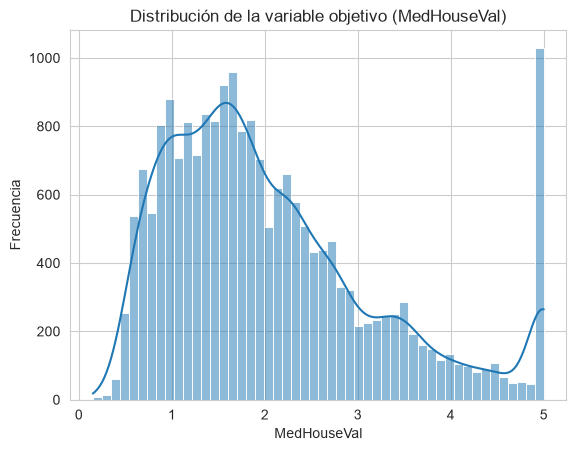

In [ ]:
# 1.5 Distribución de la variable objetivo
# Histograma con 50 intervalos y la curva de densidad (kde) encima
sns.set_style("whitegrid")
plt.figure()
sns.histplot(df['MedHouseVal'], bins=50, kde=True)
plt.title("Distribución de la variable objetivo (MedHouseVal)")
plt.xlabel("MedHouseVal")
plt.ylabel("Frecuencia")
plt.show()

### Interpretación de la sección 1

El dataset tiene 20,640 filas y 9 columnas, todas de tipo `float64` y sin valores nulos, así que no hubo que convertir tipos ni tratar faltantes. Con `target_names` se confirma que la variable a predecir es `MedHouseVal`; las otras 8 columnas (`MedInc`, `HouseAge`, `AveRooms`, `AveBedrms`, `Population`, `AveOccup`, `Latitude` y `Longitude`) son las predictoras.

`MedHouseVal` va de 0.14999 a 5.00001, con media de 2.0686, mediana de 1.797 y desviación estándar de 1.1540. Como la media es mayor que la mediana, la distribución está sesgada a la derecha, y el histograma lo confirma: la mayoría de los valores está más o menos entre 1 y 2 y hay una cola larga hacia los valores altos. También llama la atención un pico aislado en el valor máximo (5.00001), con cerca de 1,000 observaciones, lo que sugiere que la variable está topada en ese límite.

En `describe()` también se ve que algunas predictoras tienen máximos muy lejos del tercer cuartil, por ejemplo `AveRooms` (75% = 6.05 y máximo = 141.91), `AveOccup` (75% = 3.28 y máximo = 1,243.33) y `Population` (75% = 1,725 y máximo = 35,682).

---
## 2. Preparación de datos

Se definen `X` (variables predictoras) y `y` (variable objetivo), y se dividen los datos en:

- **Entrenamiento (80%)**: para ajustar el modelo.
- **Prueba (20%)**: para evaluar su capacidad de generalización en datos no vistos.

El parámetro `random_state=42` garantiza que la partición sea reproducible.

In [ ]:
# 2.1 Variables predictoras (X) y variable objetivo (y)
X = df[california.feature_names]
y = df['MedHouseVal']

print("X:", X.shape)
print("y:", y.shape)

X: (20640, 8)
y: (20640,)


In [ ]:
# 2.2 División en entrenamiento y prueba
# random_state=42 para que la división salga igual cada vez que se corre
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,       # 80% entrenamiento, 20% prueba
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (16512, 8)
X_test: (4128, 8)
y_train: (16512,)
y_test: (4128,)


### Interpretación de la sección 2

`X` quedó con 20,640 filas y 8 variables predictoras, y `y` con los 20,640 valores de `MedHouseVal`. Después de la división quedaron 16,512 observaciones para entrenamiento (80%) y 4,128 para prueba (20%), que son las proporciones que se pedían.

---
## 3. Modelo base

Se entrena un árbol de decisión **sin restricciones** (`max_depth=None`, el valor por defecto), por lo que el árbol crece hasta que se cumplen los criterios de parada por defecto. Después se revisa su tamaño (profundidad, número de hojas y de nodos) y se evalúa con **RMSE** y **R²** en entrenamiento y prueba para determinar si existe sobreajuste.

In [ ]:
# 3.1 Árbol base sin restricciones
# Con max_depth=None el árbol crece sin límite de profundidad
arbol_base = DecisionTreeRegressor(
    max_depth=None,
    random_state=42
)
arbol_base.fit(X_train, y_train)

# Tamaño del árbol, para ver qué tan complejo quedó
print("Profundidad:", arbol_base.get_depth())
print("Número de hojas:", arbol_base.get_n_leaves())
print("Número de nodos:", arbol_base.tree_.node_count)

Profundidad:

 34
Número de hojas: 15870
Número de nodos: 31739


In [ ]:
# 3.2 Funciones para evaluar
# evaluar_modelo calcula el RMSE (raíz del error cuadrático medio, en las mismas
# unidades que y) y el R² (qué parte de la variabilidad de y explica el modelo)
# en entrenamiento y en prueba
def evaluar_modelo(modelo, X_tr, y_tr, X_te, y_te, nombre='Modelo'):
    """Calcula RMSE y R² para train y test."""
    y_pred_tr = modelo.predict(X_tr)
    y_pred_te = modelo.predict(X_te)

    resultados = {
        'nombre':     nombre,
        'RMSE_train': np.sqrt(mean_squared_error(y_tr, y_pred_tr)),
        'RMSE_test':  np.sqrt(mean_squared_error(y_te, y_pred_te)),
        'R2_train':   r2_score(y_tr, y_pred_tr),
        'R2_test':    r2_score(y_te, y_pred_te),
    }
    return resultados

# imprimir_metricas muestra los resultados en una tabla y agrega la diferencia
# de RMSE entre prueba y entrenamiento (gap), que ayuda a ver si hay sobreajuste
def imprimir_metricas(res):
    gap_rmse = res['RMSE_test'] - res['RMSE_train']

    md = f"""
### Métricas: {res['nombre']}

| Métrica | Train | Test | Interpretación |
|---------|------:|-----:|----------------|
| **RMSE** | {res['RMSE_train']:.4f} | {res['RMSE_test']:.4f} | Error en $100k; menor es mejor |
| **R²**   | {res['R2_train']:.4f}   | {res['R2_test']:.4f}   | 1.0 = perfecto; >0.7 bueno |

**Gap RMSE (test − train):** {gap_rmse:.4f}
"""
    display(Markdown(md))

# 3.3 Evaluación del árbol base
res_base = evaluar_modelo(arbol_base, X_train, y_train, X_test, y_test, 'Árbol Base (sin restricciones)')
imprimir_metricas(res_base)


### Métricas: Árbol Base (sin restricciones)

| Métrica | Train | Test | Interpretación |
|---------|------:|-----:|----------------|
| **RMSE** | 0.0000 | 0.7093 | Error en $100k; menor es mejor |
| **R²**   | 1.0000   | 0.6161   | 1.0 = perfecto; >0.7 bueno |

**Gap RMSE (test − train):** 0.7093


### Interpretación de la sección 3: ¿existe sobreajuste?

Sin restricciones, el árbol llegó a una profundidad de 34, con 15,870 hojas y 31,739 nodos. Son 15,870 hojas para 16,512 observaciones de entrenamiento, o sea que casi cada observación terminó en su propia hoja.

En entrenamiento el RMSE es 0.0000 y el R² es 1.0000: el modelo reproduce los datos de entrenamiento prácticamente sin error. En prueba, en cambio, el RMSE sube a 0.7093 y el R² baja a 0.6161 (casi 0.38 menos), con un gap de 0.7093.

Por lo tanto, sí hay sobreajuste. El árbol memorizó el conjunto de entrenamiento, pero con datos que no había visto no le va igual de bien, y eso se nota en la diferencia tan grande entre el RMSE de entrenamiento y el de prueba.

---
## 4. Análisis Bias–Variance

Se entrenan árboles con `max_depth` de 1 a 21 y, para cada uno, se calcula el RMSE en entrenamiento y en prueba. La gráfica permite observar:

- **Subajuste (underfitting):** árboles poco profundos con error alto en entrenamiento y en prueba.
- **Buen ajuste:** una profundidad intermedia donde el error de prueba es mínimo.
- **Sobreajuste (overfitting):** árboles profundos con error bajo en entrenamiento pero mayor en prueba.

In [ ]:
# 4.1 RMSE según la profundidad máxima
# Profundidades de 1 a 21 (range no incluye el 22)
depths = list(range(1, 22))

rmse_train = []
rmse_test = []

# Se entrena un árbol por cada profundidad y se guarda su RMSE en train y test
for d in depths:
    model = DecisionTreeRegressor(max_depth=d, random_state=42)
    model.fit(X_train, y_train)

    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    rmse_train.append(np.sqrt(mean_squared_error(y_train, y_pred_train)))
    rmse_test.append(np.sqrt(mean_squared_error(y_test, y_pred_test)))

# Tabla con los resultados de cada profundidad
resultados_prof = pd.DataFrame({
    'max_depth': depths,
    'RMSE_train': rmse_train,
    'RMSE_test': rmse_test
})
resultados_prof

,max_depth,RMSE_train,RMSE_test
0,1,0.955523,0.971666
1,2,0.855859,0.868483
2,3,0.785957,0.801505
3,4,0.741534,0.764464
4,5,0.695948,0.724234
5,6,0.655831,0.705184
6,7,0.615396,0.675711
7,8,0.566211,0.649650
8,9,0.517161,0.644258
9,10,0.469964,0.645359


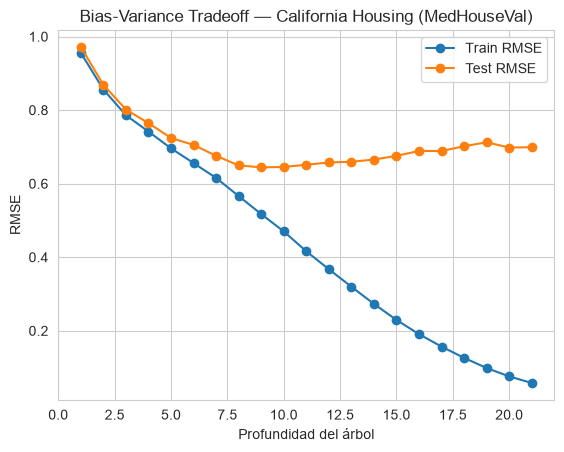

In [ ]:
# 4.2 Gráfica del RMSE en entrenamiento y prueba según la profundidad
plt.figure()
plt.plot(depths, rmse_train, marker='o', label="Train RMSE")
plt.plot(depths, rmse_test, marker='o', label="Test RMSE")

plt.xlabel("Profundidad del árbol")
plt.ylabel("RMSE")
plt.title("Bias-Variance Tradeoff — California Housing (MedHouseVal)")
plt.legend()
plt.show()

In [ ]:
# 4.3 Profundidad con el menor RMSE en prueba
# np.argmin regresa la posición del valor mínimo
best_depth = depths[np.argmin(rmse_test)]
print("Mejor max_depth:", best_depth)
print("RMSE train:", rmse_train[np.argmin(rmse_test)])
print("RMSE test:", rmse_test[np.argmin(rmse_test)])

Mejor max_depth: 9
RMSE train: 0.5171607028432692
RMSE test: 0.6442578164688181


### Interpretación de la sección 4

Con `max_depth=1` el RMSE es alto y casi igual en los dos conjuntos (0.9555 en entrenamiento y 0.9717 en prueba). El árbol es demasiado simple para captar la relación entre las variables y `MedHouseVal`, así que hay subajuste (bias alto).

Conforme aumenta la profundidad, los dos errores bajan. El RMSE de prueba llega a su mínimo con `max_depth=9` (0.6443), con un RMSE de entrenamiento de 0.5172. Las profundidades 8 (0.6497) y 10 (0.6454) quedan muy cerca, así que en esa zona la curva de prueba es casi plana.

De la profundidad 10 en adelante, el error de entrenamiento sigue bajando (de 0.4700 en 10 a 0.0579 en 21), pero el de prueba empieza a subir: 0.6756 en 15, 0.7125 en 19 (el punto más alto de esa zona) y 0.6990 en 21. La distancia entre las dos curvas pasa de 0.0161 con profundidad 1 a 0.1271 con profundidad 9 y a 0.6411 con profundidad 21, lo que muestra varianza alta y sobreajuste.

El modelo generaliza mejor con `max_depth = 9`: su RMSE de prueba (0.6443) es menor que el 0.7093 del árbol base de la sección 3.

---
## 5. Poda del árbol

Se aplica **cost-complexity pruning** mediante el parámetro `ccp_alpha`, que penaliza la complejidad del árbol: valores pequeños dejan el árbol casi completo y valores grandes eliminan más ramas.

Primero se obtiene la ruta de poda con `cost_complexity_pruning_path`, que devuelve la secuencia de valores de `ccp_alpha` relevantes para el árbol completo. Después se toma uno de cada 5 valores (`ccp_alphas = ccp_alphas[::5]`) para reducir el costo computacional, y para cada uno se entrena un árbol y se mide su RMSE en entrenamiento y prueba.

In [ ]:
# 5.1 Ruta de poda
# Se obtiene del árbol completo (sin restricciones, como el base) y regresa los
# valores de ccp_alpha en los que el árbol cambia al podarse
path = DecisionTreeRegressor(random_state=42).cost_complexity_pruning_path(X_train, y_train)

ccp_alphas = path.ccp_alphas
print("Número de valores de ccp_alpha en la ruta de poda:", len(ccp_alphas))

Número de valores de ccp_alpha en la ruta de poda: 14842


In [ ]:
# 5.2 Árboles con distintos niveles de poda
rmse_train = []
rmse_test = []
alphas = []

ccp_alphas = ccp_alphas[::5]  # uno de cada 5 valores para reducir el tiempo de cómputo
print("Número de valores de ccp_alpha evaluados:", len(ccp_alphas))

# Un árbol por cada alpha, guardando su RMSE en train y test
for alpha in ccp_alphas:
    model = DecisionTreeRegressor(random_state=42, ccp_alpha=alpha)
    model.fit(X_train, y_train)

    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    rmse_train.append(np.sqrt(mean_squared_error(y_train, y_pred_train)))
    rmse_test.append(np.sqrt(mean_squared_error(y_test, y_pred_test)))
    alphas.append(alpha)

Número de valores de ccp_alpha evaluados: 2969


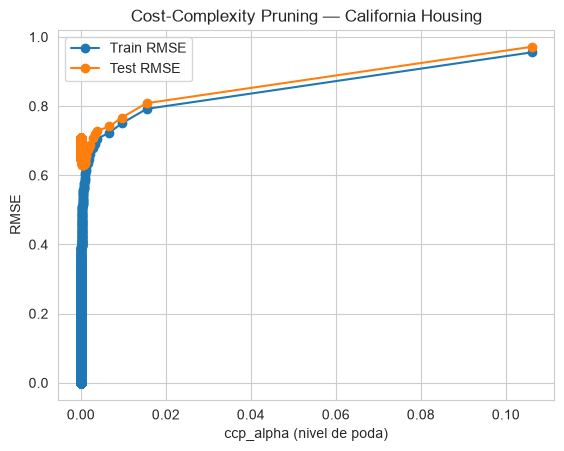

In [ ]:
# 5.3 Gráfica del RMSE según ccp_alpha
# A la izquierda queda el árbol casi completo y hacia la derecha cada vez más podado
plt.figure()
plt.plot(alphas, rmse_train, marker='o', label="Train RMSE")
plt.plot(alphas, rmse_test, marker='o', label="Test RMSE")

plt.xlabel("ccp_alpha (nivel de poda)")
plt.ylabel("RMSE")
plt.title("Cost-Complexity Pruning — California Housing")
plt.legend()
plt.show()

In [ ]:
# 5.4 Mejor valor de ccp_alpha (el de menor RMSE en prueba)
best_alpha = alphas[np.argmin(rmse_test)]
print("Mejor ccp_alpha:", best_alpha)

# Tabla para comparar tres puntos: sin poda (primer alpha), el mejor alpha
# y la poda más fuerte que se evaluó (último alpha)
i_best = np.argmin(rmse_test)
comparacion_poda = pd.DataFrame({
    'ccp_alpha': [alphas[0], alphas[i_best], alphas[-1]],
    'RMSE_train': [rmse_train[0], rmse_train[i_best], rmse_train[-1]],
    'RMSE_test': [rmse_test[0], rmse_test[i_best], rmse_test[-1]]
}, index=['Sin poda (primer alpha)', 'Mejor alpha', 'Poda máxima (último alpha)'])
comparacion_poda

Mejor ccp_alpha: 0.00048366003709678


,ccp_alpha,RMSE_train,RMSE_test
Sin poda (primer alpha),0.000000,3.014433e-16,0.709301
Mejor alpha,0.000484,5.418047e-01,0.630511
Poda máxima (último alpha),0.106096,9.555229e-01,0.971666


In [ ]:
# 5.5 Árbol podado con el mejor ccp_alpha
# También se revisa su tamaño para compararlo con el árbol base
arbol_podado = DecisionTreeRegressor(random_state=42, ccp_alpha=best_alpha)
arbol_podado.fit(X_train, y_train)

print("Profundidad:", arbol_podado.get_depth())
print("Número de hojas:", arbol_podado.get_n_leaves())
print("Número de nodos:", arbol_podado.tree_.node_count)

Profundidad: 14
Número de hojas: 189
Número de nodos: 377


In [ ]:
# 5.6 Evaluación del árbol podado, con las mismas métricas que el base
res_podado = evaluar_modelo(arbol_podado, X_train, y_train, X_test, y_test, 'Árbol Podado')
imprimir_metricas(res_podado)


### Métricas: Árbol Podado

| Métrica | Train | Test | Interpretación |
|---------|------:|-----:|----------------|
| **RMSE** | 0.5418 | 0.6305 | Error en $100k; menor es mejor |
| **R²**   | 0.7804   | 0.6966   | 1.0 = perfecto; >0.7 bueno |

**Gap RMSE (test − train):** 0.0887


### Interpretación de la sección 5: efecto de la poda en el error

`cost_complexity_pruning_path` regresó 14,842 valores de `ccp_alpha` y, con `ccp_alphas[::5]`, se evaluaron 2,969. Casi todos son muy cercanos a cero, por eso en la gráfica los puntos se amontonan a la izquierda y solo unos cuantos alphas grandes aparecen hacia la derecha.

Sin poda (`ccp_alpha = 0`), el RMSE de entrenamiento es prácticamente 0 (3.0e-16) y el de prueba es 0.7093, los mismos valores del árbol base de la sección 3.

Con el mejor valor, `ccp_alpha = 0.000484`, el RMSE de entrenamiento sube a 0.5418, pero el de prueba baja a 0.6305 y el R² de prueba sube a 0.6966 (el del árbol base era 0.6161). El gap entre prueba y entrenamiento baja de 0.7093 a 0.0887. Este árbol tiene profundidad 14, 189 hojas y 377 nodos, contra 34, 15,870 y 31,739 del árbol base, así que la poda quitó la gran mayoría de las ramas.

Con la poda más fuerte que se evaluó (`ccp_alpha = 0.1061`), los dos errores suben a 0.9555 en entrenamiento y 0.9717 en prueba, los mismos que el árbol de profundidad 1 de la sección 4. El árbol queda tan simple que cae en subajuste.

---
## 6. Interpretación de resultados

### 1. ¿El modelo base presenta sobreajuste? Explique

**Respuesta:** Sí. En la sección 3, el árbol sin restricciones tuvo en entrenamiento un RMSE de 0.0000 y un R² de 1.0000, o sea que predice el conjunto de entrenamiento sin error. En prueba, el RMSE fue de 0.7093 y el R² de 0.6161, con un gap de 0.7093. Esa diferencia tan grande entre los dos conjuntos es la señal del sobreajuste. El árbol creció hasta una profundidad de 34, con 15,870 hojas para 16,512 observaciones de entrenamiento, así que prácticamente memorizó cada observación, incluido su ruido, en vez de aprender patrones que se repitan en datos nuevos.

### 2. ¿Cómo afecta la profundidad del árbol al error?

**Respuesta:** Según la sección 4, al aumentar `max_depth` el error de entrenamiento siempre baja (de 0.9555 con profundidad 1 a 0.0579 con profundidad 21), porque el árbol tiene más divisiones para ajustarse a los datos. El error de prueba, en cambio, tiene forma de "U": primero baja, de 0.9717 con profundidad 1 hasta su mínimo de 0.6443 con profundidad 9, y luego vuelve a subir (0.7125 en profundidad 19 y 0.6990 en 21). Ahí se ve el compromiso entre bias y varianza. Con pocas divisiones el modelo es demasiado simple y se equivoca mucho en los dos conjuntos (subajuste). Con demasiadas, el error de entrenamiento sigue bajando pero el de prueba sube y la distancia entre ambos crece de 0.0161 a 0.6411 (sobreajuste). Por eso la mejor generalización está en una profundidad intermedia, la 9.

### 3. ¿Qué efecto tiene la poda en el modelo?

**Respuesta:** De acuerdo con la sección 5, la poda simplifica el árbol y reduce el sobreajuste. Con el mejor valor, `ccp_alpha = 0.000484`, el árbol pasó de 15,870 a 189 hojas y de profundidad 34 a 14. El error de entrenamiento aumentó (de 0.0000 a 0.5418), pero el de prueba bajó (de 0.7093 a 0.6305) y el R² de prueba subió de 0.6161 a 0.6966. Además, el gap entre prueba y entrenamiento pasó de 0.7093 a 0.0887, así que el árbol podado generaliza mucho mejor. Eso sí, la poda tiene un límite: con el valor más grande que se evaluó (`ccp_alpha = 0.1061`) el error sube a 0.9555 en entrenamiento y 0.9717 en prueba, porque el árbol queda demasiado simple (subajuste).

### 4. ¿Cuál configuración produce el mejor desempeño?

**Respuesta:** Estas son las tres configuraciones evaluadas en las secciones anteriores:

| Configuración | RMSE train | RMSE test |
|---|---:|---:|
| Árbol base (`max_depth=None`), sección 3 | 0.0000 | 0.7093 |
| Mejor profundidad (`max_depth=9`), sección 4 | 0.5172 | 0.6443 |
| Árbol podado (`ccp_alpha=0.000484`), sección 5 | 0.5418 | 0.6305 |

La mejor es el árbol podado con `ccp_alpha = 0.000484`. Tiene el RMSE de prueba más bajo (0.6305), un R² de prueba de 0.6966 (contra 0.6161 del árbol base) y una diferencia pequeña entre entrenamiento y prueba (0.0887). Además, es mucho más sencillo que el árbol base (189 hojas contra 15,870), así que es el que mejor equilibra el ajuste y la generalización.

### 5. ¿Qué variables son más relevantes según el modelo?

Para responder se usa el atributo `feature_importances_`, que mide cuánto contribuye cada variable a reducir el error en las divisiones del árbol. Se calcula con el árbol podado, que fue la mejor configuración en la pregunta anterior.

In [ ]:
# 6.1 Importancia de las variables
# Se ordenan de mayor a menor para ver cuáles pesan más en el modelo
importances = pd.Series(
    arbol_podado.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importances)

MedInc        0.645712
AveOccup      0.130154
Latitude      0.073474
Longitude     0.056496
HouseAge      0.041746
AveRooms      0.033516
Population    0.010419
AveBedrms     0.008483
dtype: float64


**Respuesta:** En el árbol podado, la variable más relevante es `MedInc`, con una importancia de 0.6457, cerca del 65% de la reducción total del error. Muy por detrás le siguen `AveOccup` (0.1302), `Latitude` (0.0735) y `Longitude` (0.0565); estas dos últimas indican la ubicación y juntas suman 0.1300. Las demás aportan poco: `HouseAge` (0.0417), `AveRooms` (0.0335), `Population` (0.0104) y `AveBedrms` (0.0085). O sea que el modelo predice `MedHouseVal` sobre todo con `MedInc` y, en menor medida, con la ocupación promedio y la ubicación, mientras que el resto de las variables casi no influye.